In [10]:
import numpy as np
import pandas as pd

import math
from scipy.interpolate import CubicSpline, PchipInterpolator
from scipy.optimize import least_squares
import scipy.optimize as optimize

from typing import List, Tuple
from dataclasses import dataclass

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("darkgrid")
sns.set_context("talk")

In [11]:
def bond_ytm(price, par, T, coup, freq, guess=0.05): # guess rentabilidad de partida
    freq = float(freq)
    periods = T*freq
    coupon = coup*par/freq
    dt = [(i+1)/freq for i in range(int(periods))]
    ytm_func = lambda y: \
        sum([coupon/(1+y)**(freq*t) for t in dt]) + \
        par/(1+y)**(freq*T) - price

    return (1+optimize.newton(ytm_func, guess))**(freq)-1

Datos disponibles sobre los bonos (valor nominal = 100).

In [12]:
bonds = {
    "3Y": {"coupon": 0.03625, "T": 3},  # semiannual coupon expressed in annual terms, time to maturity in years.
    "5Y": {"coupon": 0.03625, "T": 5},
    "10Y": {"coupon": 0.04255, "T": 10},
}
ytm=0.035
freq=2

In [13]:
def bond_price(par, T, ytm, coup, freq):
    freq = float(freq)
    ytm_f=(1+ytm)**(1/freq)-1 # estimamos la rentabilidad exigida fraccionada k(freq)
    periods = T*freq #  número de pagos
    coupon = coup*par/freq # valor del cupón
    dt = [(i+1) for i in range(int(periods))] # lista que incluye los exponentes
    price = sum([coupon/(1+ytm_f)**(t) for t in dt]) + \
            par/(1+ytm_f)**(freq*T)
    return price

In [14]:
VN=100
ytm=0.035
for bond, data in bonds.items():
    price = bond_price(VN, data["T"], ytm, data["coupon"], freq)
    bonds[bond]["price"] = round(price, 2)
bonds

{'3Y': {'coupon': 0.03625, 'T': 3, 'price': 100.44},
 '5Y': {'coupon': 0.03625, 'T': 5, 'price': 100.71},
 '10Y': {'coupon': 0.04255, 'T': 10, 'price': 106.59}}

## Calcular la duración de los bonos

In [ ]:
def bond_duration(VN: float, T: int, ytm: float, coup: float, freq: int) -> float:
    """
    Calcula la duración de Macaulay de un bono de cupón fijo utilizando el descuento por período.

    En primer lugar, el rendimiento anual hasta el vencimiento (YTM) se convierte en un rendimiento por período. A continuación, la función
    calcula el valor actual de cada flujo de caja, lo multiplica por su duración en años
    y lo normaliza por el precio del bono.

    Argumentos:
        VN (float): Valor nominal (capital) del bono.
        T (int): Vencimiento en años.
        ytm (float): Rendimiento anual hasta el vencimiento.
        coup (float): Tasa de cupón anual (en formato decimal).
        freq (int): Número de pagos de cupón al año (p. ej., 2 para pagos semestrales).

    Devuelve:
        flotante: Duración de Macaulay expresada en años.
    """

    n = int(T * freq)

    c = coup * VN / freq

    price = bond_price(VN, T, ytm, coup, freq)

    # Duración de cada pago en AÑOS (p. ej., 0,5; 1,0; ...; T)
    dt = np.arange(1, n + 1) / freq

    # Flujos de caja: pago de cupón en cada período; capital añadido en el último período
    cashflows = np.full(n, c)
    cashflows[-1] += VN

    # Macaulay Duration
    duration = np.sum(dt * cashflows / (1 + ytm)**dt) / price

    return float(duration)


In [16]:
# Calcular y almacenar la duración de cada bono en el diccionario
for bond_name, bond_data in bonds.items():

    # Calcula la duración de Macaulay utilizando nuestra función de duración coherente
    duration = bond_duration(
        VN,                # Valor nominal del bono
        bond_data["T"],    # Vencimiento en años
        ytm,               # rendimiento al vencimiento anual
        bond_data["coupon"],
        freq               # frecuencia de cupones por año
    )

    # Duración de la tienda redondeada a dos decimales
    bonds[bond_name]["duration"] = round(duration, 2)

bonds


{'3Y': {'coupon': 0.03625, 'T': 3, 'price': 100.44, 'duration': 2.87},
 '5Y': {'coupon': 0.03625, 'T': 5, 'price': 100.71, 'duration': 4.62},
 '10Y': {'coupon': 0.04255, 'T': 10, 'price': 106.59, 'duration': 8.31}}

## EJEMPLO INMUNIZACIÓN
Tengo que pagar 100.000 transcurrido 4.5 años determina cuantos bonos de cada tipo debo adquirir.

In [17]:
FV = 100000  # Obligación de pago futura = salida de efectivo futura = pasivo.
YTM = 0.035  # Rendimiento hasta el vencimiento = TIR anual.
TP = 4.5  # Plazo hasta el pago, en años.
VP = FV / ((1 + YTM) ** TP)  # Valor actual del pasivo.

print(f"Valor actual de la deuda: {VP:.2f}")

Valor actual de la deuda: 85658.10


In [18]:
for bond_name, bond_data in bonds.items():

    # ¿Cuántas unidades de este bono podemos comprar con el VP (presupuesto de inversión)?
    units =round(VP / bond_data["price"],0)

    # Guarda el número de unidades en el diccionario
    bonds[bond_name]["number"] = units

bonds

{'3Y': {'coupon': 0.03625,
  'T': 3,
  'price': 100.44,
  'duration': 2.87,
  'number': 853.0},
 '5Y': {'coupon': 0.03625,
  'T': 5,
  'price': 100.71,
  'duration': 4.62,
  'number': 851.0},
 '10Y': {'coupon': 0.04255,
  'T': 10,
  'price': 106.59,
  'duration': 8.31,
  'number': 804.0}}

## Si hemos invertido en los bonos a 3 años, simula cuánto dinero tendremos disponible dentro de 4,5 años si los tipos de interés se mantienen sin cambios.

### Flujos de caja reinvertidos hasta el horizonte de inversión (TP)

En esta sección calculamos el **valor futuro** de todos los flujos de caja generados por el bono a 3 años cuando se **reinvierten hasta el horizonte de inversión TP** (expresado en años).

- Los pagos de cupón y el capital se reciben en cada periodo semestral.  
- Cada flujo de caja se **reinvierte a la tasa de reinversión semestral** derivada del rendimiento anual al vencimiento (YTM).  
- El valor futuro de cada flujo de caja se obtiene capitalizándolo desde su fecha de pago hasta TP.  
- La suma de todos los flujos de caja reinvertidos representa el **valor al vencimiento** de un bono.  
- Al multiplicarlo por el número de bonos a 3 años en cartera, se obtiene el **valor total reinvertido de la posición**.

Este cálculo es coherente con el análisis del horizonte basado en la duración realizado anteriormente en este cuaderno.

In [19]:
# --- Flujos de caja reinvertidos del bono a 3 años ---

# Datos de referencia para el bono a 3 años
VN   = 100                     # Valor nominal
T    = bonds["3Y"]["T"]        # Vencimiento en años (3)
coup = bonds["3Y"]["coupon"]   # Tasa de interés nominal anual
freq = 2                       # Pagos semestrales

# El rendimiento anual utilizado para la reinversión ya se ha indicado: ytm
# Convertir el rendimiento anual al vencimiento (YTM) en un rendimiento por período (semestral)
ytm_per = (1 + ytm)**(1 / freq) - 1

# Número de períodos e índices de los períodos
n  = int(T * freq)             # p. ej., 6 períodos semestrales
dt = np.arange(1, n + 1)       # índices de período: 1, 2, ..., 6

# Cash flows per period
c = coup * VN / freq           # cupón por período
cashflows = np.full(n, c)
cashflows[-1] += VN            # añadir el capital al vencimiento

# Reinvertir cada flujo de caja hasta alcanzar el precio objetivo (en años)
remaining_periods = TP * freq - dt
cashflows_reinv = cashflows * (1 + ytm_per)**remaining_periods

# Valor total reinvertido de un bono a 3 años
reinv_one = np.sum(cashflows_reinv)

# Valor total reinvertido de todos los bonos a 3 años de la cartera
reinv_total = reinv_one * bonds["3Y"]["number"]

print(f"Tiempo hasta el horizonte: {TP} years")
print("Períodos:", dt)
print("Flujos de caja:", cashflows.round(2))
print("Flujos de caja reinvertidos en el horizonte:", cashflows_reinv.round(2))
print("Flujos de caja totales reinvertidos procedentes de un bono a 3 años:", round(reinv_one, 2))
print("Flujos de caja reinvertidos totales (todos los bonos a 3 años):", round(reinv_total, 2))


Tiempo hasta el horizonte: 4.5 years
Períodos: [1 2 3 4 5 6]
Flujos de caja: [  1.81   1.81   1.81   1.81   1.81 101.81]
Flujos de caja reinvertidos en el horizonte: [  2.08   2.04   2.01   1.98   1.94 107.2 ]
Flujos de caja totales reinvertidos procedentes de un bono a 3 años: 117.25
Flujos de caja reinvertidos totales (todos los bonos a 3 años): 100018.42


## Si hemos invertido en un bono a 5 años, simula cuánto dinero tendremos disponible dentro de 4,5 años si los tipos de interés se mantienen sin cambios.

In [ ]:
# --- Flujos de caja reinvertidos del bono a 5 años ---

# Datos de referencia para el bono a 5 años
VN   = 100                       # Valor nominal
T    = bonds["5Y"]["T"]          # Vencimiento en años (5)
coup = bonds["5Y"]["coupon"]     # Tasa de interés nominal anual
freq = 2                         # Pagos semestrales

# Rendimiento anual de reinversión ya definido: ytm
# Convertir el rendimiento anual al vencimiento (YTM) en rendimiento por período (semestral)
ytm_per = (1 + ytm)**(1 / freq) - 1

# Número de períodos de cupón e índices de período
n  = int(T * freq)               # e.g. 5 * 2 = 10 periodo
dt = np.arange(1, n + 1)         # índices de período: 1, 2, ..., 10

# Flujos de caja por período (cupones + capital al vencimiento)
c = coup * VN / freq             # cupón por período
cashflows = np.full(n, c)
cashflows[-1] += VN              # añadir el principal en el último período

# Reinversión hasta el horizonte del precio objetivo (en años)
remaining_periods = TP * freq - dt
cashflows_reinv = cashflows * (1 + ytm_per)**remaining_periods

# Valor den los flujos de caja reinvertidos a los  4.5 años
reinv_one_5Y = np.sum(cashflows_reinv)

# Valor en el año 4.5 de todos los bonos a 5 años de la cartera
reinv_total_5Y = reinv_one_5Y * bonds["5Y"]["number"]

print(f"Tiempo hasta el horizonte: {TP} years")
print("Períodos:", dt)
print("Flujos de caja (5 años):", cashflows.round(2))
print("Flujos de caja reinvertidos en el horizonte (5 años):", cashflows_reinv.round(2))
print("Flujos de caja totales reinvertidos procedentes de un bono a 5 años:", round(reinv_one_5Y, 2))
print("Flujos de caja reinvertidos totales (todos los bonos a 5 años):", round(reinv_total_5Y, 2))


Tiempo hasta el horizonte: 4.5 years
Períodos: [ 1  2  3  4  5  6  7  8  9 10]
Flujos de caja (5 años): [  1.81   1.81   1.81   1.81   1.81   1.81   1.81   1.81   1.81 101.81]
Flujos de caja reinvertidos en el horizonte (5 años): [  2.08   2.04   2.01   1.98   1.94   1.91   1.88   1.84   1.81 100.08]
Flujos de caja totales reinvertidos procedentes de un bono a 5 años: 117.57
Flujos de caja reinvertidos totales (todos los bonos a 5 años): 100050.22


## Si hemos invertido en un bono a 10 años, simula cuánto dinero tendremos disponible dentro de 4.5 años si los tipos de interés se mantienen sin cambios.

In [21]:
# Bono a 10 años
TP=4.5
TP_f=int(TP*freq)
# Calculamos el rendimiento requerido fraccionalmente k (freq) -> de anual (YTM) a semestral (ytm_f).
ytm_f = (1 + ytm) ** (1 / freq) - 1

# Número de pagos.
periods = int(bonds["10Y"]["T"] * freq)

# Valor del cupón.
coupon = bonds["10Y"]["coupon"] * VN / freq

# Plazos de pago
times = np.arange(1, periods + 1)

# Cupón en cada periodo.
cashflows = np.full(periods, coupon)

# El último periodo incluye el pago del valor nominal.
cashflows[-1] += VN

# Seleccionamos los flujos de caja que reinvertimos
cashflows_TP = cashflows[:TP_f]

# Calcular la reinversión -> interés compuesto.
# Cada cupón se reinvierte durante el tiempo restante hasta el TP.
times_reinv=np.arange(1, TP_f + 1)
cashflows_reinv = cashflows_TP * (1 + ytm_f) ** (TP_f - times_reinv)
reinv = np.sum(cashflows_TP * (1 + ytm_f) ** (TP_f - times_reinv))

#Estimamos el precio en TP.
times_price=np.arange(TP_f + 1,  bonds["10Y"]["T"]*freq+ 1)
cashflows_Price = cashflows[TP_f:]
P_TP = np.sum(cashflows_Price * (1 + ytm_f) ** (TP_f-times_price))

#Importe disponible al vencimiento de la obligación de pago de cada bono
Money=reinv+P_TP

# Dinero disponible al vencimiento de la obligación de pago
All_Money=Money*bonds["10Y"]["number"]


print(f"Tiempo restante hasta el pago: {TP} years")
print("Semestres:", times)
print("Flujos de caja:", cashflows.round(2))
print("Flujos de caja reinvertidos:", cashflows_TP.round(2))
print("Flujos de caja totales reinvertidos procedentes de bonos:", round(reinv,2))

print("Plazo tras la vencimiento de la obligación de pago",times_price)
print("Plazo tras la vencimiento de la obligación de pago",cashflows_Price)
print("Precio:", P_TP.round(2))

print("Dinero disponible", All_Money.round(2))

#print("Flujos de caja reinvertidos totales:",round(reinv*bonds["3Y"]["number"],2))

Tiempo restante hasta el pago: 4.5 years
Semestres: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]
Flujos de caja: [  2.13   2.13   2.13   2.13   2.13   2.13   2.13   2.13   2.13   2.13
   2.13   2.13   2.13   2.13   2.13   2.13   2.13   2.13   2.13 102.13]
Flujos de caja reinvertidos: [2.13 2.13 2.13 2.13 2.13 2.13 2.13 2.13 2.13]
Flujos de caja totales reinvertidos procedentes de bonos: 20.53
Plazo tras la vencimiento de la obligación de pago [10 11 12 13 14 15 16 17 18 19 20]
Plazo tras la vencimiento de la obligación de pago [  2.1275   2.1275   2.1275   2.1275   2.1275   2.1275   2.1275   2.1275
   2.1275   2.1275 102.1275]
Precio: 103.9
Dinero disponible 100043.26


In [ ]:
def money_bond(VN: float, T: float, ytm: float, coup: float, freq: int, TP: float) -> float:
    """
    Calcula el valor futuro en el horizonte TP de los flujos de caja de un bono (cupones + capital),
    suponiendo que cada pago se reinvierte al rendimiento anual hasta el vencimiento (YTM) del bono hasta TP.

    Argumentos:
        VN (float): Valor nominal del bono.
        T (float): Plazo hasta el vencimiento en años.
        ytm (float): Rendimiento anual hasta el vencimiento.
        coup (float): Tasa de cupón anual (decimal).
        freq (int): Número de pagos de cupón al año.
        TP (float): Horizonte de inversión en años.

    Devuelve:
        float: Valor futuro de todos los flujos de caja reinvertidos en el momento TP.
    """

    # 1. Rentabilidad por período (YTM fraccionado)
    ytm_per = (1 + ytm)**(1 / freq) - 1

    # 2. Número de períodos de cupón del bono
    n = int(T * freq)

    #3. Horizonte expresado en número de períodos
    horizon_periods = int(TP * freq)

    # 4. Flujos de caja: pago de cupones en cada periodo + capital al vencimiento
    c = coup * VN / freq
    cashflows = np.full(n, c)
    cashflows[-1] += VN


    # 5. Plazos de pago en los períodos (1, 2, …, n)
    dt = np.arange(1, n + 1)

    # 6. Reinvertir cada flujo de caja hasta alcanzar el objetivo de beneficio (TP)
    future_value = np.sum(cashflows * (1 + ytm_per)**(horizon_periods - dt))


    return float(future_value)


In [23]:
TP=4.5
ytm=0.035
money_bond(100,bonds["5Y"]["T"], ytm, bonds["5Y"]["coupon"], freq, TP)*bonds["5Y"]["number"]

100050.2182607948

### Importe neto en el horizonte de pago (TP)

Este cálculo determina cuánto dinero hay disponible en la fecha de pago **tras reinvertir todos los flujos de caja del bono** (cupones y capital) hasta el TP.  
A continuación, el valor en el horizonte de la posición del bono se compara con la **obligación futura**:

- Un **resultado positivo** significa que la estrategia de bonos cubre íntegramente la obligación (superávit).  
- Un **resultado igual a cero** indica una inmunización perfecta.  
- Un **resultado negativo** implica un déficit en el TP.

Esta es la métrica clave que se utiliza para evaluar las estrategias de inmunización basadas en la duración.

In [24]:
def result(bond_data: dict, ytm: float, freq: int, horizon_T: float,
           FV_obligation: float, VN: float = 100) -> float:
    """
    Calcula el importe neto disponible en el horizonte de pago horizon_T tras
    cumplir con la obligación futura FV_obligation.

    La función calcula el valor en el horizonte de la posición en bonos
    (todos los cupones y el capital reinvertidos hasta horizon_T)
    y resta el importe del pasivo.

    Argumentos:
        bond_data (dict): Información del bono con las siguientes claves:
            'coupon'   : tipo de cupón anual (decimal)
            'T'        : vencimiento en años
            'price'    : precio actual del bono
            'number'   : número de bonos en cartera
            'duration' : duración de Macaulay (años)
        ytm (float): Rendimiento anual utilizado para la reinversión.
        freq (entero): Número de pagos de cupón al año (p. ej., 2).
        horizon_T (flotante): Horizonte de inversión en años.
        FV_obligation (flotante): Pago vencido en horizon_T.
        VN (flotante, opcional): Valor nominal del bono (por defecto = 100).

    Rendimientos:
        float: Importe neto disponible tras pagar la obligación.
    """

    # Valor en el horizonte de un bono
    horizon_value_one = money_bond(
        VN,
        bond_data["T"],
        ytm,
        bond_data["coupon"],
        freq,
        horizon_T
    )

    # Valor total de la posición completa a lo largo del horizonte temporal
    total_horizon_value = horizon_value_one * bond_data["number"]

    # Importe neto tras haber cubierto la obligación
    net_amount = total_horizon_value - FV_obligation

    return float(net_amount)


In [25]:
result(bonds["10Y"], ytm, freq, TP, FV)

43.259879627483315

In [26]:
results = {
    name: result(bond_data, ytm, freq, TP, FV, VN)
    for name, bond_data in bonds.items()
}

In [27]:
df_results = pd.DataFrame.from_dict(results, orient='index', columns=['result'])
print(df_results)

        result
3Y   18.417610
5Y   50.218261
10Y  43.259880


Simula cuánto dinero habrá disponible dentro de 4,5 años si los tipos de interés suben un 1 %.

In [28]:
mu = 0.01  # 1% incremento rentabidilidad de mercado.
results_mu = {
    name: result(bond_data, ytm+mu, freq, TP, FV, VN)
    for name, bond_data in bonds.items()
}

In [29]:
df_results_mu = pd.DataFrame.from_dict(results_mu, orient='index', columns=['result'])
print(df_results_mu.round(2))

      result
3Y   1599.48
5Y    -59.69
10Y -3520.90


Simula cuánto dinero habrá disponible dentro de 4,5 años si los tipos de interés bajan un -1 %

In [30]:
mu = -0.01  # 1% increase in rates.
results_mu = {
    name: result(bond_data, ytm+mu, freq, TP, FV, VN)
    for name, bond_data in bonds.items()
}

In [31]:
df_results_mu = pd.DataFrame.from_dict(results_mu, orient='index', columns=['result'])
print(df_results_mu.round(2))

      result
3Y  -1550.97
5Y    171.42
10Y  3857.57


Veamos cómo varía el excedente al variar $\mu$: (-0,02; 0,02)

In [32]:
mus = np.linspace(-0.02, 0.02, 101)  # -200bp to +200bp = -0.02 to +0.02

# Lista donde guardamos cada simulación en forma de diccionario
simulations = []

for mu in mus:
    results_mu = {
      name: result(bond_data, ytm+mu, freq, TP, FV, VN)
      for name, bond_data in bonds.items()
      }
    results_mu["mu"] = mu   # Importante: añadir la columna con el shock
    simulations.append(results_mu)

# Convertir todo en DataFrame
df_sims = pd.DataFrame(simulations).set_index("mu")

In [33]:
df_sims

,3Y,5Y,10Y
mu,,,
-0.0200,-3108.723089,304.000539,7940.103793
-0.0196,-3046.635825,298.478008,7771.411857
-0.0192,-2984.530006,292.973800,7603.178936
-0.0188,-2922.405631,287.487909,7435.403729
-0.0184,-2860.262697,282.020332,7268.084939
...,...,...,...
0.0184,2936.620205,-143.326813,-6333.685997
0.0188,3000.500217,-147.112730,-6463.677597
0.0192,3064.399029,-150.880774,-6593.317466


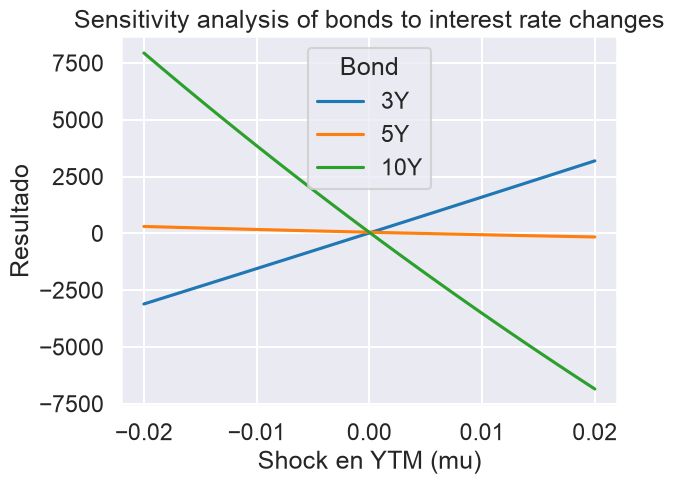

In [34]:
df_sims[["3Y", "5Y", "10Y"]].plot()

plt.title("Sensitivity analysis of bonds to interest rate changes")
plt.xlabel("Shock en YTM (mu)")
plt.ylabel("Resultado")
plt.grid(True)
plt.legend(title="Bond")   # opcional
plt.show()

### Aplicamos una estrategia de inmunización alternativa combinando los bonos a 3 y a 10 años:

1. **Ponderación por duración**

$$ w_3 D_{3} + (1-w_3) D_{10} = H
\quad\Rightarrow\quad
w_3 = \frac{H - D_{10}}{D_{3} - D_{10}},\;\; w_{10}=1-w_3 $$

donde:
* $H=4,5$ años es el horizonte del pasivo
* $D_3,D_{10}$ son las duraciones de Macaulay de cada bono

2. **Escalar (importe nocional total) para que coincida con el valor actual (PV) del pasivo**

$$ N \cdot \big(w_3 P_3 + w_{10} P_{10}\big) = PV_{\text{pasivo}}
\quad\Rightarrow\quad
N = \frac{PV_{\text{pasivo}}}{w_3 P_3 + w_{10} P_{10}} $$

Entonces, el número (en 100 unidades nominales) para cada bono es $N_3=N\,w_3,\; N_{10}=N\,w_{10}$.

In [35]:
# 1. Ponderación según la duración de Macaulay para alcanzar la duración objetivo H = 4,5 años.
D3 = bonds["3Y"]["duration"]  # Plazo del bono a 3 años.
D10 = bonds["10Y"]["duration"]  # Plazo del bono a 10 años.
H = TP  # Duración prevista = tiempo hasta el pago.

# Calcular las ponderaciones para cada tipo de bono.
w3 = (H - D10) / (D3 - D10)
w10 = 1.0 - w3

print(f"w3 = {w3:.4f}, w10 = {w10:.4f}")

#2. Importe (nominal total) que se corresponda con el valor actual del pasivo.
PV_L = FV * (1 + ytm) ** (-TP)  # Liability present value.
P3 = bonds["3Y"]["price"]  # Price of the 3Y bond.
P10 = bonds["10Y"]["price"]  # Price of the 10Y bond.

# Calcula el número total de «bloques» de 100 unidades nominales que hay en la cartera.
N = PV_L / (w3 * P3 + w10 * P10)

# Número de «bloques» por tipo de bono.
N3 = N * w3
N10 = N * w10

print(f"PV liability = {PV_L:.2f}")
print(f"N = {N:.2f} -> N3 = {N3:.2f}, N10 = {N10:.2f}")

# Redondear a int.
N3_i = round(N3, 0)
N10_i = round(N10, 0)
PV_round = N3_i * P3 + N10_i * P10
Dur_port = (N3_i * P3 * D3 + N10_i * P10 * D10) / PV_round

print(f"(Rounded) N3 = {N3_i:.0f}, N10 = {N10_i:.0f}, PV_port = {PV_round:,.2f}, Dur_port = {Dur_port:.3f}")

w3 = 0.7004, w10 = 0.2996
PV liability = 85658.10
N = 837.46 -> N3 = 586.53, N10 = 250.93
(Rounded) N3 = 587, N10 = 251, PV_port = 85,712.37, Dur_port = 4.568


In [36]:
#mu=+0.02
money_3Y=money_bond(100,bonds["3Y"]["T"], ytm+mu, bonds["3Y"]["coupon"], freq, TP)*N3_i
money_10Y=money_bond(100,bonds["10Y"]["T"], ytm+mu, bonds["10Y"]["coupon"], freq, TP)*N10_i
Inmu=money_3Y+money_10Y-FV
print(Inmu)

92.65066463558469
